<a href="https://colab.research.google.com/github/rrdaks23/Forestry_RS/blob/main/Benteng_ekologis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [26]:
import ee
import geemap
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import statsmodels.api as sm
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
import os
import shutil
from google.colab import drive, output
import matplotlib.colors as mcolors
import joblib
from IPython.display import display

drive.mount('/content/drive')
# Autentikasi dan Inisialisasi Google Earth Engine
try:
    ee.Initialize(project='tesyeye')
except Exception as e:
    ee.Authenticate()
    ee.Initialize(project='tesyeye')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [27]:
# Panggil Aset Spasial Utama (Sesuaikan path ID GEE Anda)
tngl_boundary = ee.FeatureCollection("projects/tesyeye/assets/KEL_Aceh")
roads_asset = ee.FeatureCollection("projects/tesyeye/assets/jalan_utama")
facilities_asset = ee.FeatureCollection("projects/tesyeye/assets/toponomi_ibukota")
forest_2019_asset = ee.FeatureCollection("projects/tesyeye/assets/DSS_fixkel19")
forest_2021_asset = ee.FeatureCollection("projects/tesyeye/assets/DSS_fixkel21")
forest_2025_asset = ee.FeatureCollection("projects/tesyeye/assets/DSS_fixfixkel25")

In [28]:
# Aset Hutan Non-TNGL Tambahan
non_tngl_forest_2019_asset = ee.FeatureCollection("projects/tesyeye/assets/erase_non_kel19")
non_tngl_forest_2021_asset = ee.FeatureCollection("projects/tesyeye/assets/erase_non_kel21")
non_tngl_forest_2025_asset = ee.FeatureCollection("projects/tesyeye/assets/erase_non_kel25")

In [29]:
# 1. Buat Buffer 100 km & Wilayah Luar (Outside TNGL Buffer)
tngl_geom = tngl_boundary.geometry()
buffer_geom = tngl_geom.buffer(100000, 500)  # [FIX] 100 km (satuan meter), sebelumnya 1.000 km
outside_buffer_geom = buffer_geom.difference(tngl_geom, 500)

buffer_feature = ee.FeatureCollection([ee.Feature(buffer_geom)])
outside_feature = ee.FeatureCollection([ee.Feature(outside_buffer_geom)])

In [30]:
# 2. Variabel Spasial Pendukung
road_image = roads_asset.distance(searchRadius=1500).unmask(1500).rename('Dist_Road')  # [FIX] unmask agar piksel jauh tidak terbuang saat sampling
facility_image = facilities_asset.distance(searchRadius=1500).unmask(1500).rename('Dist_Facility')
dem = ee.Image('NASA/NASADEM_HGT/001').select('elevation').clip(buffer_geom).rename('Elevation')
slope = ee.Terrain.slope(dem).rename('Slope')
tngl_distance = tngl_boundary.distance(searchRadius=150000).unmask(150000).rename('Dist_To_TNGL')  # [FIX] Geometry.distance() bukan citra

In [31]:
# ==========================================
# SECTION 2: PEMROSESAN CITRA RESOLUSI TERTINGGI (2019 & 2025)
# ==========================================
print("Memproses Citra Optik & Termal Resolusi Tinggi...")

def maskS2clouds(image):
    # [FIX] QA60 tidak lagi terisi untuk citra Sentinel-2 terbaru -> pakai Cloud Score+
    return image.updateMask(image.select('cs_cdf').gte(0.5))

def maskL8sr(image):
    qa = image.select('QA_PIXEL')
    cloudShadowBitMask = (1 << 4)
    cloudsBitMask = (1 << 3)
    mask = qa.bitwiseAnd(cloudShadowBitMask).eq(0).And(qa.bitwiseAnd(cloudsBitMask).eq(0))
    return image.updateMask(mask)

def processHighRes(start_date, end_date):
    csp = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
    s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          .filterBounds(buffer_geom)
          .filterDate(start_date, end_date)
          .linkCollection(csp, ['cs_cdf'])
          .map(maskS2clouds) # Implementasi Cloud Masking S2
          .median())

    ndvi = s2.normalizedDifference(['B8', 'B4']).rename('NDVI')
    ndmi = s2.normalizedDifference(['B8', 'B11']).rename('NDMI')
    evi = s2.expression(
        '2.5 * ((B8 - B4) / (B8 + 6 * B4 - 7.5 * B2 + 10000))',
        {'B8': s2.select('B8'), 'B4': s2.select('B4'), 'B2': s2.select('B2')}
    ).rename('EVI')

    bsi = s2.expression(
        '((B11 + B4) - (B8 + B2)) / ((B11 + B4) + (B8 + B2))',
        {'B11': s2.select('B11'), 'B4': s2.select('B4'), 'B8': s2.select('B8'), 'B2': s2.select('B2')}
    ).rename('BSI')

    # [FIX] NDWI, MNDWI, SAVI dihitung sebagai bagian dari tubuh fungsi
    ndwi = s2.normalizedDifference(['B3', 'B8']).rename('NDWI')
    mndwi = s2.normalizedDifference(['B3', 'B11']).rename('MNDWI')
    savi = s2.expression('1.5 * (B8 - B4) / (B8 + B4 + 5000)',
                         {'B8': s2.select('B8'), 'B4': s2.select('B4')}).rename('SAVI')

    l8 = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
          .filterBounds(buffer_geom)
          .filterDate(start_date, end_date)
          .map(maskL8sr) # Implementasi Cloud Masking L8
          .median())

    lst = l8.select('ST_B10').multiply(0.00341802).add(149.0).subtract(273.15).rename('LST')
    ndbi = l8.normalizedDifference(['SR_B6', 'SR_B5']).rename('NDBI')

    # Ambil variabel VIIRS
    viirs_all = (ee.ImageCollection('NOAA/VIIRS/DNB/ANNUAL_V21')
                 .merge(ee.ImageCollection('NOAA/VIIRS/DNB/ANNUAL_V22')))
    yr_end = f"{int(start_date[:4]) + 1}-01-01"
    viirs = (ee.Image(viirs_all.filterDate('2012-01-01', yr_end)
                      .sort('system:time_start', False).first())
             .select('median').rename('Nighttime_Lights').unmask(0))

    # UHI & UTFVI
    mean_lst = ee.Number(lst.reduceRegion(reducer=ee.Reducer.mean(), geometry=buffer_geom, scale=1000, maxPixels=1e9, bestEffort=True, tileScale=4).get('LST'))
    std_lst = ee.Number(lst.reduceRegion(reducer=ee.Reducer.stdDev(), geometry=buffer_geom, scale=1000, maxPixels=1e9, bestEffort=True, tileScale=4).get('LST'))
    uhi = lst.subtract(ee.Image.constant(mean_lst)).divide(ee.Image.constant(std_lst)).rename('UHI')
    utfvi = lst.subtract(ee.Image.constant(mean_lst)).divide(lst.add(273.15)).rename('UTFVI')

    return ee.Image.cat([ndvi, ndmi, evi, bsi, ndwi, mndwi, savi, lst, ndbi, uhi, utfvi, viirs,
                         dem, slope, road_image, facility_image, tngl_distance]).clip(buffer_geom)

Memproses Citra Optik & Termal Resolusi Tinggi...


In [32]:
# Cell ini sengaja dikosongkan karena kodenya telah dipindahkan ke cell 1pYG-CPi4wiV demi menjaga integritas fungsi.

In [33]:
# Cell ini sengaja dikosongkan karena kodenya telah dipindahkan ke cell 1pYG-CPi4wiV demi menjaga integritas fungsi.

In [34]:
# Cell ini sengaja dikosongkan karena kodenya telah dipindahkan ke cell 1pYG-CPi4wiV demi menjaga integritas fungsi.

In [35]:
image_2019 = processHighRes('2019-01-01', '2019-12-31')
image_2021 = processHighRes('2021-01-01', '2021-12-31')
image_2025 = processHighRes('2025-01-01', '2025-12-31')
print("Komposit citra resolusi tinggi tahun 2019 dan 2025 berhasil dimuat.")

Komposit citra resolusi tinggi tahun 2019 dan 2025 berhasil dimuat.


In [36]:
# ==========================================
# SECTION 3: PENDUGAAN BIOMASSA & CADANGAN KARBON (SAR + OPTIK)
# ==========================================
def estimateBiomassAndCarbon(image, start_date, end_date):
    ndvi_band = image.select('NDVI')

    # Tambahan Data Sentinel-1 SAR untuk Struktur Kanopi 3D
    s1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
          .filterBounds(buffer_geom)
          .filterDate(start_date, end_date)
          .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
          .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH'))
          .filter(ee.Filter.eq('instrumentMode', 'IW'))
          .median())
    vh = s1.select('VH').rename('SAR_VH')

    # Model hibrida: Optik (NDVI) + Radar (SAR VH)
    # Rumus disesuaikan untuk mengkombinasikan pantulan struktur (SAR) dan kehijauan (NDVI)
    agb = image.expression(
        'ndvi < 0.2 ? 0 : (exp(3.0 * ndvi) * 10) + (vh + 30) * 2',
        {'ndvi': ndvi_band, 'vh': vh}
    ).clamp(0, 500).rename('AGB')

    carbon = agb.multiply(0.5).rename('Carbon_Stock')
    return image.addBands(agb).addBands(carbon).addBands(vh)

image_2019 = estimateBiomassAndCarbon(image_2019, '2019-01-01', '2019-12-31')
image_2021 = estimateBiomassAndCarbon(image_2021, '2021-01-01', '2021-12-31')
image_2025 = estimateBiomassAndCarbon(image_2025, '2025-01-01', '2025-12-31')

In [37]:
# ==========================================
# SECTION 4: ANALISIS PERUBAHAN KARBON & IKLIM MIKRO (LUAS HEKTAR & PRINT)
# ==========================================
print("Menganalisis Perubahan Hutan dan Topeng Permukiman (TNGL & Non-TNGL)...")
# Rasterisasi Hutan TNGL
forest_tngl_19 = ee.Image().byte().paint(forest_2019_asset, 1).unmask(0)
forest_tngl_21 = ee.Image().byte().paint(forest_2021_asset, 1).unmask(0)
forest_tngl_25 = ee.Image().byte().paint(forest_2025_asset, 1).unmask(0)

Menganalisis Perubahan Hutan dan Topeng Permukiman (TNGL & Non-TNGL)...


In [38]:
# Rasterisasi Hutan Non-TNGL
forest_nontngl_19 = ee.Image().byte().paint(non_tngl_forest_2019_asset, 1).unmask(0)
forest_nontngl_21 = ee.Image().byte().paint(non_tngl_forest_2021_asset, 1).unmask(0)
forest_nontngl_25 = ee.Image().byte().paint(non_tngl_forest_2025_asset, 1).unmask(0)

In [39]:
# Gabungan Hutan (TNGL + Non-TNGL) untuk tiap tahun
total_forest_2019_img = forest_tngl_19.Or(forest_nontngl_19).rename('total_forest')
total_forest_2021_img = forest_tngl_21.Or(forest_nontngl_21).rename('total_forest')
total_forest_2025_img = forest_tngl_25.Or(forest_nontngl_25).rename('total_forest')

In [40]:
# Topeng Permukiman (Non-Hutan) KHUSUS AREA BUFFER 100 KM
settlement_mask_2019 = total_forest_2019_img.eq(0).updateMask(total_forest_2019_img.clip(outside_buffer_geom).mask()).rename('Settlement_Zone_2019')
settlement_mask_2021 = total_forest_2021_img.eq(0).updateMask(total_forest_2021_img.clip(outside_buffer_geom).mask()).rename('Settlement_Zone_2021')
settlement_mask_2025 = total_forest_2025_img.eq(0).updateMask(total_forest_2025_img.clip(outside_buffer_geom).mask()).rename('Settlement_Zone_2025')

In [41]:
# 1. Delta Perubahan Karbon & Iklim Mikro
forest_loss_img = total_forest_2019_img.eq(1).And(total_forest_2025_img.eq(0)).rename('loss')
loss_area_img = ee.Image.pixelArea().divide(10000).updateMask(forest_loss_img)
total_forest_loss_ha = loss_area_img.reduceRegion(
    reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4
).getInfo().get('area') or 0  # [FIX] nama band hasil pixelArea adalah 'area', bukan 'loss'

# 3. Perhitungan Carbon Rate (2019-2025)
carbon_diff = image_2025.select('Carbon_Stock').subtract(image_2019.select('Carbon_Stock')).rename('Carbon_Diff')
carbon_rate = carbon_diff.divide(6).rename('Carbon_Rate')
# Memasukkan Carbon_Rate ke citra 2025
image_2025 = image_2025.addBands(carbon_rate)

# Delta Perubahan SEMUA Parameter Iklim Mikro & Karbon (2025 - 2019)
microclimate_params = ['Carbon_Stock', 'LST', 'UHI', 'UTFVI', 'NDVI', 'EVI', 'NDMI', 'NDBI', 'BSI']
diff_images_list = [carbon_rate]

for param in microclimate_params:
    diff_band = image_2025.select(param).subtract(image_2019.select(param)).rename(f'{param}_Diff')
    diff_images_list.append(diff_band)

all_diffs_img = ee.Image.cat(diff_images_list)  # [FIX] dipindah keluar loop

In [42]:
# 5. PEMBATASAN DAN PENGHITUNGAN LUASAN SPASIAL (HEKTAR) TIAP PARAMETER
pixel_area_ha = ee.Image.pixelArea().divide(10000)

# Carbon Stock (Surplus vs Defisit)
surplus_ha = pixel_area_ha.updateMask(carbon_diff.gt(0)).reduceRegion(reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4).getInfo().get('area') or 0
deficit_ha = pixel_area_ha.updateMask(carbon_diff.lt(0)).reduceRegion(reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4).getInfo().get('area') or 0

# LST (Pendinginan vs Pemanasan)
lst_diff = all_diffs_img.select('LST_Diff')
cooling_ha = pixel_area_ha.updateMask(lst_diff.lt(0)).reduceRegion(reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4).getInfo().get('area') or 0
warming_ha = pixel_area_ha.updateMask(lst_diff.gt(0)).reduceRegion(reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4).getInfo().get('area') or 0

# NDVI (Degradasi vs Peningkatan Vegetasi)
ndvi_diff = all_diffs_img.select('NDVI_Diff')
ndvi_increase_ha = pixel_area_ha.updateMask(ndvi_diff.gt(0.05)).reduceRegion(reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4).getInfo().get('area') or 0
ndvi_decline_ha = pixel_area_ha.updateMask(ndvi_diff.lt(-0.05)).reduceRegion(reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4).getInfo().get('area') or 0

# NDBI (Ekspansi Bangunan / Alih Fungsi Lahan)
ndbi_diff = all_diffs_img.select('NDBI_Diff')
ndbi_expansion_ha = pixel_area_ha.updateMask(ndbi_diff.gt(0.05)).reduceRegion(reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4).getInfo().get('area') or 0

# UTFVI (Peningkatan Stres Termal)
utfvi_diff = all_diffs_img.select('UTFVI_Diff')
utfvi_worsened_ha = pixel_area_ha.updateMask(utfvi_diff.gt(0.005)).reduceRegion(reducer=ee.Reducer.sum(), geometry=buffer_geom, scale=60, maxPixels=1e9, bestEffort=True, tileScale=4).getInfo().get('area') or 0

print("\n" + "="*70)
print("HASIL ANALISIS PERUBAHAN LUASAN SPASIAL (2019 - 2025)")
print("="*70)
print(f" [HUTAN]    Kehilangan Hutan Total (Deforestasi) : {total_forest_loss_ha:,.2f} Ha")
print(f" [KARBON]   Wilayah Surplus Karbon (Penyerapan) : {surplus_ha:,.2f} Ha")
print(f" [KARBON]   Wilayah Defisit Karbon (Pelepasan) : {deficit_ha:,.2f} Ha")
print(f" [SUHU LST] Wilayah Pendinginan Suhu (Cooling)  : {cooling_ha:,.2f} Ha")
print(f" [SUHU LST] Wilayah Pemanasan Suhu (Warming)    : {warming_ha:,.2f} Ha")
print(f" [VEGETASI] Wilayah Peningkatan Kerapatan NDVI  : {ndvi_increase_ha:,.2f} Ha")
print(f" [VEGETASI] Wilayah Degradasi Kerapatan NDVI   : {ndvi_decline_ha:,.2f} Ha")
print(f" [BUILD-UP] Wilayah Ekspansi Bangunan (NDBI)   : {ndbi_expansion_ha:,.2f} Ha")
print(f" [TERMAL]   Wilayah Peningkatan Stres UTFVI     : {utfvi_worsened_ha:,.2f} Ha")
print("="*70)


HASIL ANALISIS PERUBAHAN LUASAN SPASIAL (2019 - 2025)
 [HUTAN]    Kehilangan Hutan Total (Deforestasi) : 31,745.90 Ha
 [KARBON]   Wilayah Surplus Karbon (Penyerapan) : 3,411,164.57 Ha
 [KARBON]   Wilayah Defisit Karbon (Pelepasan) : 3,600,596.60 Ha
 [SUHU LST] Wilayah Pendinginan Suhu (Cooling)  : 7,810,506.36 Ha
 [SUHU LST] Wilayah Pemanasan Suhu (Warming)    : 5,920,652.93 Ha
 [VEGETASI] Wilayah Peningkatan Kerapatan NDVI  : 2,557,319.92 Ha
 [VEGETASI] Wilayah Degradasi Kerapatan NDVI   : 3,277,126.32 Ha
 [BUILD-UP] Wilayah Ekspansi Bangunan (NDBI)   : 477,736.41 Ha
 [TERMAL]   Wilayah Peningkatan Stres UTFVI     : 4,582,790.44 Ha


In [47]:
# ==========================================
# SECTION 6: UJI STATISTIK KOMPARATIF, ML & VALIDITAS MODEL
# ==========================================
print("\nMengekstrak sampel piksel untuk uji statistik komparatif & validasi...")

all_features = ['Carbon_Stock', 'Carbon_Rate', 'LST', 'UHI', 'UTFVI', 'NDVI', 'EVI', 'NDMI', 'NDWI', 'SAVI', 'NDBI', 'BSI', 'MNDWI', 'SAR_VH']
sample_bands = image_2025.select(all_features)

# Sampel Dalam TNGL Inti - ditingkatkan scale ke 500 untuk menghindari limit memori GEE
sample_inside = sample_bands.sample(region=tngl_geom, scale=1000, numPixels=1500, seed=42, geometries=False)
df_inside = geemap.ee_to_df(sample_inside).dropna()
df_inside['Zone'] = 'Inside_TNGL'

# Sampel Luar Buffer KHUSUS PERMUKIMAN (Non-Hutan 2025) - Ditingkatkan ke 2000m karena luasnya area buffer luar
settlement_img_masked = sample_bands.updateMask(settlement_mask_2025).updateMask(sample_bands.select('MNDWI').lt(0))
sample_outside = settlement_img_masked.sample(region=outside_buffer_geom, scale=1000, numPixels=1500, seed=42, geometries=False)
df_outside = geemap.ee_to_df(sample_outside).dropna()
df_outside['Zone'] = 'Outside_Settlement'

df_comparison_stats = pd.concat([df_inside, df_outside])

# Independent T-Test Komprehensif Seluruh Parameter
stat_results = {}
for feat in all_features:
    t_stat, p_val = stats.ttest_ind(df_inside[feat], df_outside[feat], equal_var=False)
    stat_results[feat] = {
        'Mean_Inside': df_inside[feat].mean(),
        'Mean_Outside': df_outside[feat].mean(),
        't_stat': t_stat,
        'p_val': p_val
    }

df_stats_all = pd.DataFrame(stat_results).T.reset_index().rename(columns={'index':'Parameter'})


Mengekstrak sampel piksel untuk uji statistik komparatif & validasi...


In [49]:
# 2. Machine Learning & Uji Validitas Model (Random Forest Regression untuk Karbon/AGB)
# Menggunakan klasifikasi 1 untuk kehilangan hutan dan 0 untuk hutan bertahan
combined_class = forest_loss_img.unmask(0).rename('class')  # [FIX] variabel lama (forest_2025_img, cover_raster, loss_raster) tidak pernah didefinisikan

sample_image_ml = image_2025.addBands(combined_class)
sample_points_ml = sample_image_ml.sample(region=buffer_geom, scale=1000, numPixels=2000, seed=42, geometries=False)
df_stat = geemap.ee_to_df(sample_points_ml).dropna()

X_ols_cols = ['Elevation', 'Slope', 'Dist_Road', 'Dist_To_TNGL', 'NDVI', 'EVI', 'NDMI', 'NDBI', 'BSI', 'SAR_VH']
X_ols = sm.add_constant(df_stat[X_ols_cols])
y_ols = df_stat['LST']
ols_model = sm.OLS(y_ols, X_ols).fit()

# Machine Learning Random Forest Regressor untuk Prediksi Biomassa / Karbon
X_rf_cols = ['Elevation', 'Slope', 'Dist_Road', 'Dist_To_TNGL', 'NDVI', 'EVI', 'NDWI', 'NDMI', 'SAVI', 'NDBI', 'BSI', 'LST', 'SAR_VH']
X_rf = df_stat[X_rf_cols]
y_rf = df_stat['AGB']

X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_rf, y_rf, test_size=0.2, random_state=42)
rf_val_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_val_model.fit(X_train_v, y_train_v)
y_pred_v = rf_val_model.predict(X_test_v)

r2_val = r2_score(y_test_v, y_pred_v)
rmse_val = np.sqrt(mean_squared_error(y_test_v, y_pred_v))
mae_val = mean_absolute_error(y_test_v, y_pred_v)
feature_imp = pd.Series(rf_val_model.feature_importances_, index=X_rf.columns).sort_values(ascending=False)

In [50]:
# 3.Ambil variabel peringkat teratas untuk laporan otomatis
top_carbon_factor = feature_imp.index[0]
top_carbon_score = feature_imp.iloc[0]
second_carbon_factor = feature_imp.index[1] if len(feature_imp) > 1 else ""

print("\n" + "="*70)
print("RANKING FAKTOR UTAMA PENGARUH CADANGAN KARBON (RANDOM FOREST)")
print("="*70)
print(feature_imp)
print("="*70)

print("\n" + "="*70)
print("PENGARUH FAKTOR TERHADAP IKLIM MIKRO / LST (OLS REGRESSION)")
print("="*70)
ols_summary_print = pd.DataFrame({
    'Koefisien (Pengaruh)': ols_model.params.drop('const', errors='ignore'),
    'P-Value (Signifikansi)': ols_model.pvalues.drop('const', errors='ignore')
}).sort_values(by='Koefisien (Pengaruh)', ascending=False)
print(ols_summary_print)
print(f"Model OLS R-squared: {ols_model.rsquared:.4f}")
print("="*70)

print("\n--- HASIL UJI VALIDITAS MODEL RANDOM FOREST (CADANGAN KARBON/AGB) ---")
print(f" - Koefisien Determinasi (R² Score) : {r2_val:.4f}")
print(f" - Root Mean Square Error (RMSE)    : {rmse_val:.4f} Ton/Ha")
print(f" - Mean Absolute Error (MAE)        : {mae_val:.4f} Ton/Ha")



RANKING FAKTOR UTAMA PENGARUH CADANGAN KARBON (RANDOM FOREST)
NDVI            0.378610
EVI             0.357265
SAVI            0.206879
NDWI            0.056466
SAR_VH          0.000632
NDBI            0.000028
NDMI            0.000023
BSI             0.000023
Dist_To_TNGL    0.000020
Slope           0.000020
LST             0.000017
Elevation       0.000014
Dist_Road       0.000002
dtype: float64

PENGARUH FAKTOR TERHADAP IKLIM MIKRO / LST (OLS REGRESSION)
              Koefisien (Pengaruh)  P-Value (Signifikansi)
EVI                       6.414289            5.522300e-03
BSI                       5.112196            4.684224e-03
SAR_VH                    0.323328            9.243736e-13
Dist_To_TNGL              0.000014            3.079851e-05
Dist_Road                -0.001033            4.985429e-02
Elevation                -0.004472            4.913070e-76
Slope                    -0.189807            6.288887e-11
NDBI                     -1.520371            7.414751e-01
NDMI 

In [52]:
# ==========================================
# SECTION 7: DEEP LEARNING (LSTM) 8-FITUR KUARTALAN SPATIO-TEMPORAL
# ==========================================
print("\n=== SECTION 7: Pelatihan Model Deep Learning LSTM (8 Fitur Kuartalan) ===")

lstm_features = ['NDVI', 'EVI', 'NDMI', 'LST', 'NDBI', 'UHI', 'UTFVI', 'SAR_VH']
years = list(range(2019, 2026))
quarters = [('01-01', '03-31'), ('04-01', '06-30'), ('07-01', '09-30'), ('10-01', '12-31')]

lstm_points = ee.FeatureCollection.randomPoints(buffer_geom, 200, 42)
time_series_data = []

for year in years:
    for q_start, q_end in quarters:
        start_q = f"{year}-{q_start}"
        end_q = f"{year}-{q_end}"

        q_img_opt = processHighRes(start_q, end_q)
        q_img_sar = estimateBiomassAndCarbon(q_img_opt, start_q, end_q)

        q_sample = q_img_sar.select(lstm_features).sampleRegions(
            collection=lstm_points, scale=120, geometries=True
        )

        try:  # [FIX] kuartal yang gagal dilewati, tidak menghentikan seluruh skrip
            extracted_feat = q_sample.getInfo()['features']
        except Exception as err:
            print(f"   [SKIP] {start_q}: {err}")
            continue
        for feat in extracted_feat:
            props = feat['properties']
            coords = feat['geometry']['coordinates']
            row_data = [coords[0], coords[1], f"{year}-{q_start}"]
            row_data.extend([props.get(f, np.nan) for f in lstm_features])  # [FIX] NaN, bukan 0 (0 °C palsu)
            time_series_data.append(row_data)
        print(f"   Kuartal {start_q} selesai ({len(extracted_feat)} titik valid)")

cols = ['lon', 'lat', 'time'] + lstm_features
df_lstm = pd.DataFrame(time_series_data, columns=cols)
df_lstm[lstm_features] = df_lstm[lstm_features].astype(float)  # [FIX] NaN diinterpolasi di bawah, bukan diisi 0

# [FIX] Titik yang kehilangan kuartal (awan) diinterpolasi; titik dengan >50% data kosong dibuang
all_times = [f"{y}-{qs}" for y in years for qs, _ in quarters]
timesteps = len(all_times)
num_points = df_lstm.groupby(['lon', 'lat']).ngroups

X_data = np.zeros((max(num_points, 1), timesteps, len(lstm_features)))
point_idx = 0
for point, point_df in df_lstm.groupby(['lon', 'lat']):
    series = point_df.drop_duplicates('time').set_index('time').reindex(all_times)[lstm_features]
    if series.isna().all(axis=1).sum() > timesteps * 0.5:
        continue
    series = series.interpolate(limit_direction='both')
    if series.isna().any().any():
        continue
    X_data[point_idx] = series.values
    point_idx += 1

X_data = X_data[:point_idx]
print(f"Titik valid untuk LSTM: {point_idx} dari {num_points}")

if point_idx >= 10:  # [FIX] LSTM hanya dilatih bila data cukup (menghindari crash)
    scaler = MinMaxScaler()
    X_scaled = scaler.fit_transform(X_data.reshape(-1, len(lstm_features))).reshape(X_data.shape)

    X_train, y_train = X_scaled[:, :-1, :], X_scaled[:, -1, 3] # Index 3 = LST

    dl_model = Sequential([
        tf.keras.Input(shape=(X_train.shape[1], len(lstm_features))),  # [FIX] Diganti dengan tf.keras.Input langsung
        LSTM(64, return_sequences=True),                      # [FIX] activation relu dihapus (default tanh)
        Dropout(0.2),
        LSTM(32),
        Dense(1)
    ])
    dl_model.compile(optimizer='adam', loss='mse')
    hist = dl_model.fit(X_train, y_train, epochs=20, batch_size=16, validation_split=0.2, verbose=0)
    print("Model Deep Learning LSTM 8-Fitur Berhasil Dilatih!")
    print(f"   Loss akhir (train) = {hist.history['loss'][-1]:.5f} | Loss akhir (val) = {hist.history['val_loss'][-1]:.5f}")
else:
    print("[PERINGATAN] Data deret waktu tidak cukup untuk melatih LSTM; bagian ini dilewati.")


=== SECTION 7: Pelatihan Model Deep Learning LSTM (8 Fitur Kuartalan) ===
   Kuartal 2019-01-01 selesai (186 titik valid)
   Kuartal 2019-04-01 selesai (162 titik valid)
   Kuartal 2019-07-01 selesai (171 titik valid)
   Kuartal 2019-10-01 selesai (154 titik valid)
   Kuartal 2020-01-01 selesai (187 titik valid)


   Kuartal 2020-04-01 selesai (172 titik valid)
   Kuartal 2020-07-01 selesai (172 titik valid)
   Kuartal 2020-10-01 selesai (94 titik valid)
   Kuartal 2021-01-01 selesai (191 titik valid)
   Kuartal 2021-04-01 selesai (150 titik valid)
   Kuartal 2021-07-01 selesai (142 titik valid)
   Kuartal 2021-10-01 selesai (188 titik valid)
   Kuartal 2022-01-01 selesai (182 titik valid)
   Kuartal 2022-04-01 selesai (173 titik valid)
   Kuartal 2022-07-01 selesai (175 titik valid)
   Kuartal 2022-10-01 selesai (121 titik valid)
   Kuartal 2023-01-01 selesai (189 titik valid)
   Kuartal 2023-04-01 selesai (183 titik valid)
   Kuartal 2023-07-01 selesai (176 titik valid)
   Kuartal 2023-10-01 selesai (145 titik valid)
   Kuartal 2024-01-01 selesai (191 titik valid)
   Kuartal 2024-04-01 selesai (195 titik valid)
   Kuartal 2024-07-01 selesai (185 titik valid)
   Kuartal 2024-10-01 selesai (168 titik valid)
   Kuartal 2025-01-01 selesai (178 titik valid)
   Kuartal 2025-04-01 selesai (178 titik 


=== SECTION 8: Membuat Visualisasi Grafik Analisis Spasial, Validitas OLS, & ML ===


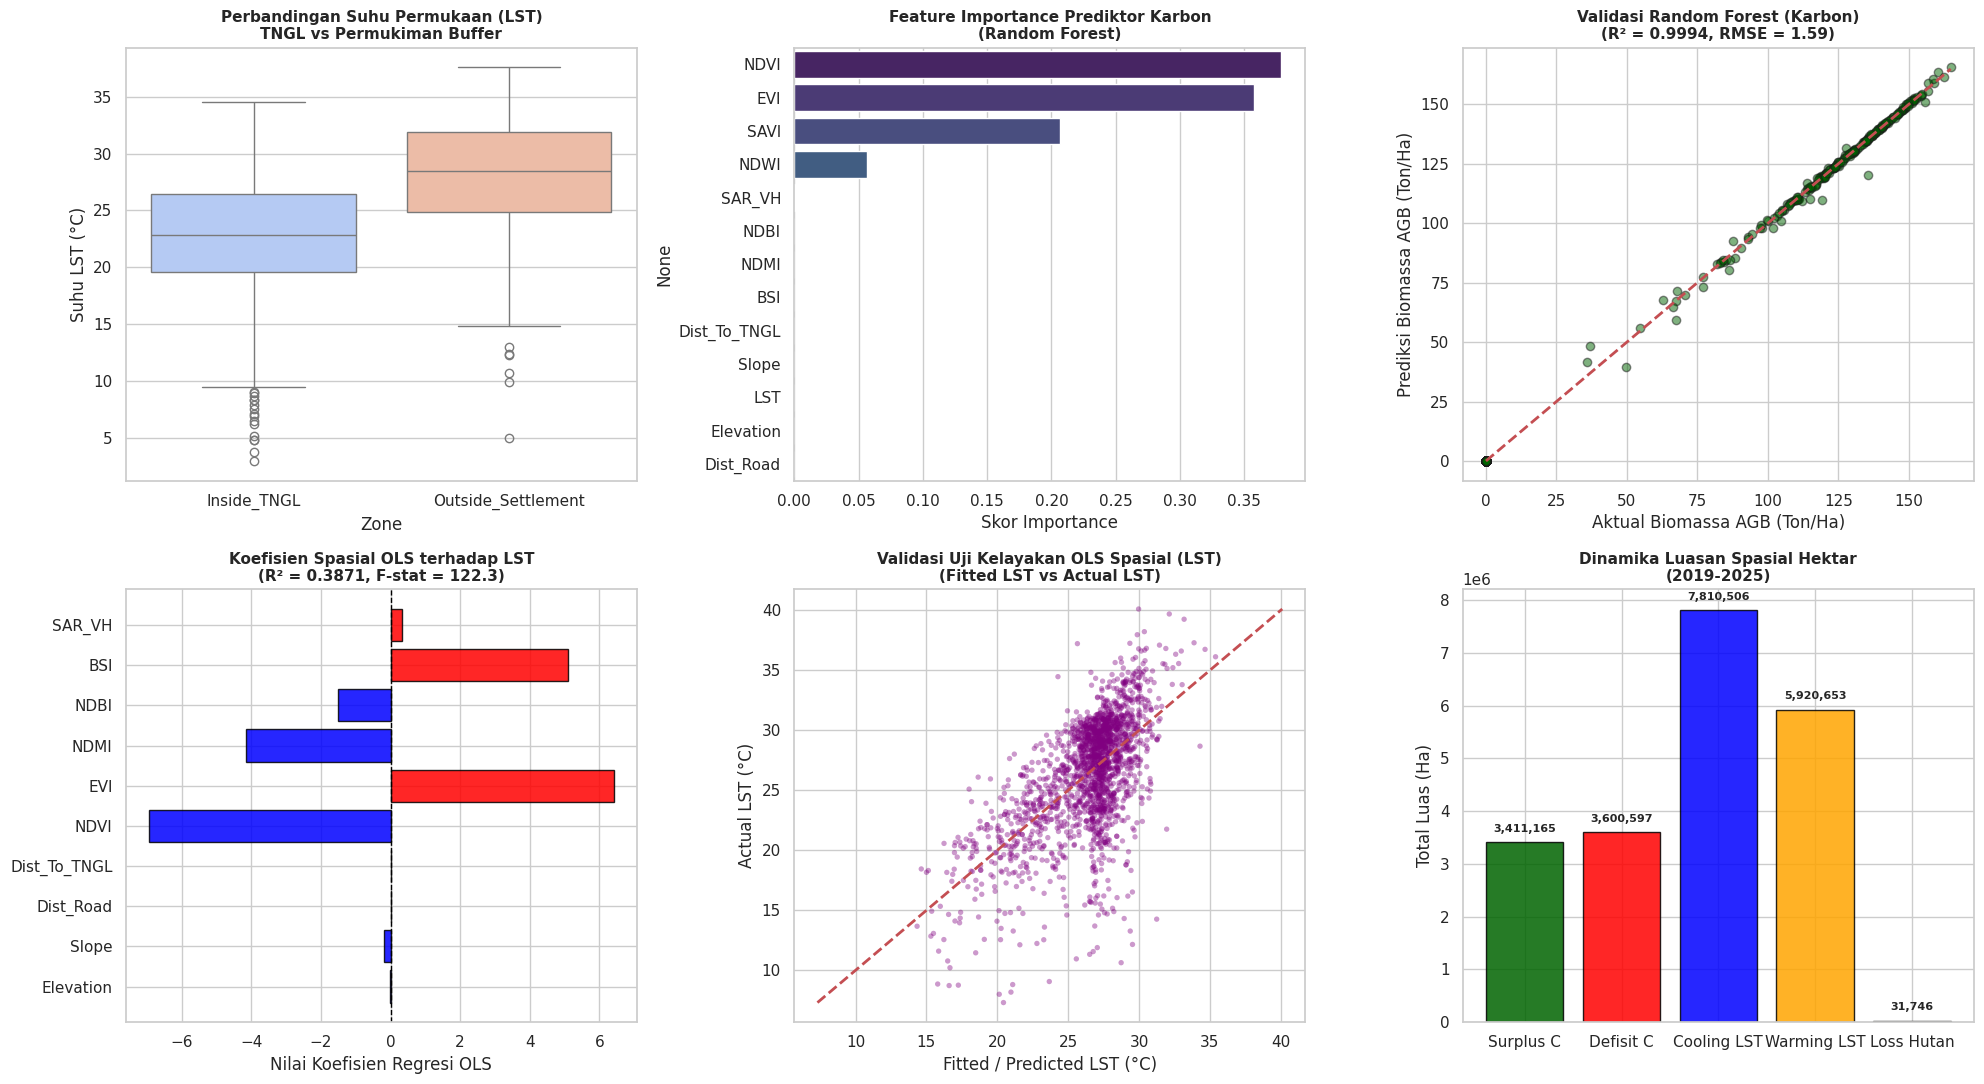

In [53]:
# ==========================================
# SECTION 8: VISUALISASI GRAFIK HASIL ANALISIS & VALIDITAS OLS SPASIAL
# ==========================================
print("\n=== SECTION 8: Membuat Visualisasi Grafik Analisis Spasial, Validitas OLS, & ML ===")

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(20, 11))

# 1. Boxplot Suhu LST (Inside TNGL vs Permukiman Buffer)
sns.boxplot(x='Zone', y='LST', hue='Zone', data=df_comparison_stats, ax=axes[0, 0], palette="coolwarm", legend=False)
axes[0, 0].set_title('Perbandingan Suhu Permukaan (LST)\nTNGL vs Permukiman Buffer', fontweight='bold', fontsize=11)
axes[0, 0].set_ylabel('Suhu LST (°C)')

# 2. Random Forest Feature Importance (Prediktor Karbon)
sns.barplot(x=feature_imp.values, y=feature_imp.index, hue=feature_imp.index, ax=axes[0, 1], palette="viridis", legend=False)
axes[0, 1].set_title('Feature Importance Prediktor Karbon\n(Random Forest)', fontweight='bold', fontsize=11)
axes[0, 1].set_xlabel('Skor Importance')

# 3. Validitas Model Random Forest (Scatter Prediksi vs Aktual AGB)
axes[0, 2].scatter(y_test_v, y_pred_v, alpha=0.5, color='darkgreen', edgecolors='k')
axes[0, 2].plot([y_test_v.min(), y_test_v.max()], [y_test_v.min(), y_test_v.max()], 'r--', lw=2)
axes[0, 2].set_title(f'Validasi Random Forest (Karbon)\n(R² = {r2_val:.4f}, RMSE = {rmse_val:.2f})', fontweight='bold', fontsize=11)
axes[0, 2].set_xlabel('Aktual Biomassa AGB (Ton/Ha)')
axes[0, 2].set_ylabel('Prediksi Biomassa AGB (Ton/Ha)')

# 4. Uji Validitas OLS Spasial (Plot Koefisien Pengaruh Parameter terhadap LST)
ols_params = ols_model.params.drop('const', errors='ignore')
ols_pvalues = ols_model.pvalues.drop('const', errors='ignore')
colors_ols = ['red' if coef > 0 else 'blue' for coef in ols_params.values]

axes[1, 0].barh(ols_params.index, ols_params.values, color=colors_ols, edgecolor='black', alpha=0.85)
axes[1, 0].axvline(0, color='black', linestyle='--', linewidth=1)
axes[1, 0].set_title(f'Koefisien Spasial OLS terhadap LST\n(R² = {ols_model.rsquared:.4f}, F-stat = {ols_model.fvalue:.1f})', fontweight='bold', fontsize=11)
axes[1, 0].set_xlabel('Nilai Koefisien Regresi OLS')

# 5. Uji Kelayakan & Fit Model OLS Spasial (Fitted LST vs Actual LST)
y_ols_fitted = ols_model.fittedvalues
axes[1, 1].scatter(y_ols_fitted, y_ols, alpha=0.4, color='purple', edgecolors='none', s=15)
axes[1, 1].plot([y_ols.min(), y_ols.max()], [y_ols.min(), y_ols.max()], 'r--', lw=2)
axes[1, 1].set_title(f'Validasi Uji Kelayakan OLS Spasial (LST)\n(Fitted LST vs Actual LST)', fontweight='bold', fontsize=11)
axes[1, 1].set_xlabel('Fitted / Predicted LST (°C)')
axes[1, 1].set_ylabel('Actual LST (°C)')

# 6. Bar Chart Dinamika Luasan Spasial Hektar
area_labels = ['Surplus C', 'Defisit C', 'Cooling LST', 'Warming LST', 'Loss Hutan']
area_values = [surplus_ha, deficit_ha, cooling_ha, warming_ha, total_forest_loss_ha]
bars = axes[1, 2].bar(area_labels, area_values, color=['darkgreen', 'red', 'blue', 'orange', 'saddlebrown'], edgecolor='black', alpha=0.85)
axes[1, 2].set_title('Dinamika Luasan Spasial Hektar\n(2019-2025)', fontweight='bold', fontsize=11)
axes[1, 2].set_ylabel('Total Luas (Ha)')

for bar in bars:
    yval = bar.get_height()
    axes[1, 2].text(bar.get_x() + bar.get_width()/2, yval + (max(area_values)*0.02), f'{yval:,.0f}', ha='center', va='bottom', fontsize=8, fontweight='bold')

plt.tight_layout()
fig_path = '/tmp/visualisasi_statistik_tngl.png'
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
plt.show()  # [FIX] tampilkan di Colab
plt.close()

In [54]:
# ==========================================
# SECTION 9: VISUALISASI PETA INTERAKTIF GEEMAP (SEMUA DATA, PARAMETER & TAHUN)
# ==========================================
print("\n=== SECTION 9: Menyiapkan Peta Interaktif Geemap (Semua Data, Parameter & Tahun) ===")

try:  # [FIX] agar peta tampil di Colab
    output.enable_custom_widget_manager()
except Exception:
    pass
Map = geemap.Map(center=[3.5, 97.5], zoom=8)
Map.add_basemap('HYBRID')

# 1. Parameter Visualisasi Standar untuk Seluruh Indeks
ndviVis = {'min': -0.1, 'max': 0.9, 'palette': ['blue', 'white', 'yellow', 'limegreen', 'darkgreen']}
eviVis = {'min': 0, 'max': 0.8, 'palette': ['white', 'yellow', 'limegreen', 'darkgreen']}
ndmiVis = {'min': -0.3, 'max': 0.4, 'palette': ['brown', 'yellow', 'cyan', 'blue']}
ndwiVis = {'min': -0.5, 'max': 0.5, 'palette': ['red', 'white', 'blue']}
saviVis = {'min': 0, 'max': 0.8, 'palette': ['brown', 'yellow', 'darkgreen']}
bsiVis = {'min': -0.3, 'max': 0.3, 'palette': ['darkgreen', 'yellow', 'brown', 'red']}
mndwiVis = {'min': -0.4, 'max': 0.4, 'palette': ['brown', 'white', 'blue']}

lstVis = {'min': 18, 'max': 34, 'palette': ['blue', 'cyan', 'yellow', 'orange', 'red']}
ndbiVis = {'min': -0.3, 'max': 0.3, 'palette': ['darkgreen', 'white', 'brown', 'red']}
uhiVis = {'min': -2, 'max': 2, 'palette': ['blue', 'cyan', 'white', 'yellow', 'red']}
utfviVis = {'min': -0.05, 'max': 0.05, 'palette': ['blue', 'cyan', 'white', 'orange', 'red']}

carbonVis = {'min': 0, 'max': 250, 'palette': ['red', 'orange', 'yellow', 'limegreen', 'darkgreen']}
agbVis = {'min': 0, 'max': 500, 'palette': ['brown', 'yellow', 'limegreen', 'darkgreen']}
sarVis = {'min': -25, 'max': 0, 'palette': ['black', 'white']}

diffVis = {'min': -0.3, 'max': 0.3, 'palette': ['red', 'white', 'green']}
diffLstVis = {'min': -5, 'max': 5, 'palette': ['blue', 'white', 'red']}
diffNdbiVis = {'min': -0.3, 'max': 0.3, 'palette': ['green', 'white', 'red']}
diffCarbonVis = {'min': -50, 'max': 50, 'palette': ['red', 'white', 'green']}
rateVis = {'min': -5, 'max': 5, 'palette': ['red', 'yellow', 'darkgreen']}

# 2. Layer Vektor (Batas Administrasi & Buffer)
Map.addLayer(tngl_boundary, {'color': 'green', 'fillColor': '00000000'}, 'Batas TNGL Inti')
Map.addLayer(outside_feature, {'color': 'orange', 'fillColor': '00000000'}, 'Zona Buffer 100km Outside TNGL')
Map.addLayer(buffer_feature, {'color': 'blue', 'fillColor': '00000000'}, 'Batas Radius Buffer 100km (Total)', False)

# 3. Layer Tutupan Hutan, Deforestasi, & Permukiman Buffer Multi-Tahun (2019, 2021, 2025)
Map.addLayer(total_forest_2019_img.updateMask(total_forest_2019_img.eq(1)), {'palette': ['darkgreen']}, 'Tutupan Hutan Total 2019', False)
Map.addLayer(total_forest_2021_img.updateMask(total_forest_2021_img.eq(1)), {'palette': ['forestgreen']}, 'Tutupan Hutan Total 2021', False)
Map.addLayer(total_forest_2025_img.updateMask(total_forest_2025_img.eq(1)), {'palette': ['limegreen']}, 'Tutupan Hutan Total 2025', True)
Map.addLayer(forest_loss_img.updateMask(forest_loss_img.eq(1)), {'palette': ['red']}, 'Deforestasi / Kehilangan Hutan (2019-2025)', True)

Map.addLayer(settlement_mask_2019.updateMask(settlement_mask_2019), {'palette': ['yellow']}, 'Zona Permukiman Buffer 2019', False)
Map.addLayer(settlement_mask_2021.updateMask(settlement_mask_2021), {'palette': ['orange']}, 'Zona Permukiman Buffer 2021', False)
Map.addLayer(settlement_mask_2025.updateMask(settlement_mask_2025), {'palette': ['red']}, 'Zona Permukiman Buffer 2025', True)

# 4. Layer Indeks Spektral Optik per Tahun (2019, 2021, 2025)
years_data = [('2019', image_2019), ('2021', image_2021), ('2025', image_2025)]

for yr_name, img_yr in years_data:
    is_default = (yr_name == '2025')
    Map.addLayer(img_yr.select('NDVI'), ndviVis, f'NDVI {yr_name}', False)
    Map.addLayer(img_yr.select('EVI'), eviVis, f'EVI {yr_name}', False)
    Map.addLayer(img_yr.select('NDMI'), ndmiVis, f'NDMI {yr_name}', False)
    Map.addLayer(img_yr.select('NDWI'), ndwiVis, f'NDWI {yr_name}', False)
    Map.addLayer(img_yr.select('SAVI'), saviVis, f'SAVI {yr_name}', False)
    Map.addLayer(img_yr.select('BSI'), bsiVis, f'BSI {yr_name}', False)
    Map.addLayer(img_yr.select('MNDWI'), mndwiVis, f'MNDWI {yr_name}', False)
    Map.addLayer(img_yr.select('NDBI'), ndbiVis, f'NDBI {yr_name}', is_default)

# 5. Layer Termal & Iklim Mikro per Tahun (2019, 2021, 2025)
for yr_name, img_yr in years_data:
    is_default = (yr_name == '2025')
    Map.addLayer(img_yr.select('LST'), lstVis, f'LST Suhu (°C) {yr_name}', is_default)
    Map.addLayer(img_yr.select('UHI'), uhiVis, f'UHI {yr_name}', False)
    Map.addLayer(img_yr.select('UTFVI'), utfviVis, f'UTFVI Stres Termal {yr_name}', False)

# 6. Layer Karbon, Biomassa & SAR Radar per Tahun (2019, 2021, 2025)
for yr_name, img_yr in years_data:
    is_default = (yr_name == '2025')
    Map.addLayer(img_yr.select('AGB'), agbVis, f'AGB Biomassa {yr_name}', False)
    Map.addLayer(img_yr.select('Carbon_Stock'), carbonVis, f'Carbon Stock (Ton/Ha) {yr_name}', is_default)
    Map.addLayer(img_yr.select('SAR_VH'), sarVis, f'Sentinel-1 SAR VH {yr_name}', False)

# 7. Layer Laju Carbon Rate & Delta Perubahan Spasial Seluruh Parameter (2025 vs 2019)
Map.addLayer(all_diffs_img.select('Carbon_Rate'), rateVis, 'Laju Carbon Rate (t/ha/tahun)', True)
Map.addLayer(all_diffs_img.select('Carbon_Stock_Diff'), diffCarbonVis, 'Delta Carbon Stock (2025-2019)', True)
Map.addLayer(all_diffs_img.select('LST_Diff'), diffLstVis, 'Delta LST Suhu (2025-2019)', True)
Map.addLayer(all_diffs_img.select('UTFVI_Diff'), {'min': -0.05, 'max': 0.05, 'palette': ['blue', 'white', 'red']},  # [FIX] rentang disesuaikan
              'Delta UTFVI Stres Termal (2025-2019)', False)
Map.addLayer(all_diffs_img.select('NDBI_Diff'), diffNdbiVis, 'Delta NDBI Kawasan Terbangun (2025-2019)', False)
Map.addLayer(all_diffs_img.select('NDVI_Diff'), diffVis, 'Delta NDVI Vegetasi (2025-2019)', False)
Map.addLayer(all_diffs_img.select('EVI_Diff'), diffVis, 'Delta EVI (2025-2019)', False)
Map.addLayer(all_diffs_img.select('NDMI_Diff'), diffVis, 'Delta NDMI (2025-2019)', False)
Map.addLayer(all_diffs_img.select('BSI_Diff'), diffNdbiVis, 'Delta BSI Lahan Terbuka (2025-2019)', False)

# ==========================================
# 8. LEGENDA INTERAKTIF LENGKAP MULTI-PARAMETER
# ==========================================

# Legenda 1: Tutupan Hutan, Deforestasi & Penempatan
legend_forest = {
    'Hutan Terlindungi': 'limegreen',
    'Deforestasi (2019-2025)': 'red',
    'Permukiman Buffer (2025)': 'red',
    'Permukiman Buffer (2021)': 'orange',
    'Permukiman Buffer (2019)': 'yellow'
}

# Legenda 2: Cadangan Karbon (Carbon Stock)
legend_carbon = {
    'Sangat Rendah (< 50 Ton/Ha)': 'red',
    'Rendah (50 - 100 Ton/Ha)': 'orange',
    'Sedang (100 - 150 Ton/Ha)': 'yellow',
    'Tinggi (150 - 200 Ton/Ha)': 'limegreen',
    'Sangat Tinggi (> 200 Ton/Ha)': 'darkgreen'
}

# Legenda 3: Suhu Permukaan (LST)
legend_lst = {
    'Sangat Sejuk (< 20 °C)': 'blue',
    'Sejuk / Normal (20 - 24 °C)': 'cyan',
    'Sedang (24 - 28 °C)': 'yellow',
    'Hangat (28 - 32 °C)': 'orange',
    'Panas (> 32 °C)': 'red'
}

# Legenda 4: Stres Termal (UTFVI)
legend_utfvi = {
    'Tanpa Stres Termal (< 0)': 'blue',
    'Stres Termal Ringan (0 - 0.005)': 'cyan',
    'Stres Termal Sedang (0.005 - 0.010)': 'yellow',
    'Stres Termal Kuat (0.010 - 0.020)': 'orange',
    'Stres Termal Sangat Kuat (> 0.020)': 'red'
}

# Legenda 5: Indeks Terbangun & Lahan Terbuka (NDBI & BSI)
legend_ndbi = {
    'Vegetasi Rapat / Air (< -0.10)': 'darkgreen',
    'Vegetasi Jarang / Transisi (-0.10 - 0.05)': 'white',
    'Lahan Terbuka / BSI Tinggi (0.05 - 0.15)': 'brown',
    'Kawasan Terbangun Padat (> 0.15)': 'red'
}

# Legenda 6: Kehijauan Vegetasi (NDVI & EVI)
legend_ndvi = {
    'Air / Non-Vegetasi (< 0.1)': 'blue',
    'Lahan Terbuka / Terbangun (0.1 - 0.3)': 'yellow',
    'Vegetasi Sedang / Semak (0.3 - 0.6)': 'limegreen',
    'Hutan Kanopi Rapat (> 0.6)': 'darkgreen'
}

# Legenda 7: Delta Perubahan & Carbon Rate
legend_delta = {
    'Pelepasan Karbon / Pemanasan LST Tinggi': 'red',
    'Perubahan Netral / Stabil': 'white',
    'Penyerapan Karbon / Pendinginan LST Tinggi': 'green'
}

# [FIX] geemap membutuhkan kode hex (bukan nama warna)
def _to_hex(d):
    return {k: mcolors.to_hex(v)[1:] for k, v in d.items()}

legend_forest = _to_hex(legend_forest)
legend_carbon = _to_hex(legend_carbon)
legend_lst = _to_hex(legend_lst)
legend_utfvi = _to_hex(legend_utfvi)
legend_ndbi = _to_hex(legend_ndbi)
legend_ndvi = _to_hex(legend_ndvi)
legend_delta = _to_hex(legend_delta)

# Menambahkan Seluruh Legenda ke Peta Interaktif
Map.add_legend(title="Tutupan Hutan & Deforestasi", legend_dict=legend_forest)
Map.add_legend(title="Cadangan Karbon (Carbon Stock)", legend_dict=legend_carbon)
Map.add_legend(title="Suhu Permukaan (LST °C)", legend_dict=legend_lst)
Map.add_legend(title="Stres Termal (UTFVI)", legend_dict=legend_utfvi)
Map.add_legend(title="Indeks Terbangun & Lahan Terbuka (NDBI/BSI)", legend_dict=legend_ndbi)
Map.add_legend(title="Kehijauan Vegetasi (NDVI)", legend_dict=legend_ndvi)
Map.add_legend(title="Delta Perubahan & Carbon Rate", legend_dict=legend_delta)

try:
    Map.save('/tmp/Peta_Benteng_Ekologis_TNGL.html')
except Exception as err:
    print(f"[PERINGATAN] Peta HTML gagal disimpan: {err}")
display(Map)



=== SECTION 9: Menyiapkan Peta Interaktif Geemap (Semua Data, Parameter & Tahun) ===


Map(center=[3.5, 97.5], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', t…

In [55]:
# ==========================================
# SECTION 10: EKSPOR TERPISAH & KOMPREHENSIF KE GOOGLE DRIVE (SEMUA HASIL)
# ==========================================
print("\nMulai proses ekspor komprehensif ke Google Drive...")
import joblib

# (Drive sudah di-mount di awal skrip)
output_dir = '/content/drive/MyDrive/TNGL_Ultimate_Research_Lengkap'
os.makedirs(output_dir, exist_ok=True)

# 1. Ekspor Data Tabular (CSV) Uji Statistik & Parameter
df_validation_summary = pd.DataFrame({'Metric_Name': ['R2_Score', 'RMSE_Ton_Ha', 'MAE_Ton_Ha'], 'Value': [r2_val, rmse_val, mae_val]})
df_validation_summary.to_csv(f'{output_dir}/model_validation_metrics.csv', index=False)

df_carbon_area_summary = pd.DataFrame({
    'Change_Category': ['Surplus Karbon (Sink)', 'Defisit Karbon (Emisi)', 'Pendinginan Suhu (Cooling)', 'Pemanasan Suhu (Warming)', 'Kehilangan Hutan (Deforestasi)'],
    'Total_Area_Hectares': [surplus_ha, deficit_ha, cooling_ha, warming_ha, total_forest_loss_ha]
})
df_carbon_area_summary.to_csv(f'{output_dir}/spatial_change_area_ha.csv', index=False)

# Menyimpan hasil uji t-test seluruh parameter
df_stats_all.to_csv(f'{output_dir}/statistical_test_all_parameters.csv', index=False)

ols_summary_df = pd.DataFrame({'Coefficient': ols_model.params, 'Std_Error': ols_model.bse, 't_value': ols_model.tvalues, 'P_value': ols_model.pvalues})
ols_summary_df.to_csv(f'{output_dir}/ols_regression_summary_table.csv')

# 2. Ekspor Visualisasi Grafik (PNG) - Memperbaiki referensi variabel gambar
shutil.copy(fig_path, f'{output_dir}/visualisasi_komprehensif_statistik_tngl.png')
if os.path.exists('/tmp/Peta_Benteng_Ekologis_TNGL.html'):  # [FIX] peta HTML ikut disalin ke Drive
    shutil.copy('/tmp/Peta_Benteng_Ekologis_TNGL.html', f'{output_dir}/Peta_Benteng_Ekologis_TNGL.html')

# 3. Ekspor Model ML (Random Forest) dan DL (LSTM)
joblib.dump(rf_val_model, f'{output_dir}/random_forest_carbon_model.pkl')
if 'dl_model' in locals():
    dl_model.save(f'{output_dir}/lstm_deep_learning_model_8features.keras')

# 4. Ekspor Data Raster Spasial (GeoTIFF) via Geemap Per Tahun & Per Parameter
print("Mengekspor data raster per tahun...")
# [FIX] geemap.ee_export_image_to_drive berisiko bentrok argumen (maxPixels) -> pakai ee.batch langsung
EXPORT_SCALE = 100  # ubah ke 30 jika ruang Google Drive cukup (file jauh lebih besar)
def export_to_drive(image, description):
    task = ee.batch.Export.image.toDrive(
        image=image.toFloat(), description=description,
        folder='TNGL_Ultimate_Research_Lengkap', region=buffer_geom,
        scale=EXPORT_SCALE, crs='EPSG:4326', maxPixels=1e13)
    task.start()

export_params = ['Carbon_Stock', 'LST', 'NDBI', 'SAR_VH', 'NDVI', 'UHI', 'UTFVI']
images_to_export = {'2019': image_2019, '2021': image_2021, '2025': image_2025}

for year, img in images_to_export.items():
    for param in export_params:
        export_to_drive(img.select(param), f'{param}_{year}')

# Ekspor Layer Tutupan & Kehilangan Hutan
export_to_drive(total_forest_2019_img, 'Tutupan_Hutan_2019')
export_to_drive(total_forest_2021_img, 'Tutupan_Hutan_2021')
export_to_drive(total_forest_2025_img, 'Tutupan_Hutan_2025')
export_to_drive(forest_loss_img, 'Kehilangan_Hutan_2019_2025')

# Ekspor Layer Delta / Selisih
export_to_drive(carbon_diff, 'Carbon_Stock_Delta_2025_vs_2019')
export_to_drive(ndbi_diff, 'NDBI_Delta_2025_vs_2019')
export_to_drive(lst_diff, 'LST_Delta_2025_vs_2019')

print("-> CSV/model/grafik tersimpan. Task ekspor GeoTIFF sudah DIKIRIM; pantau di https://code.earthengine.google.com/tasks")


Mulai proses ekspor komprehensif ke Google Drive...
Mengekspor data raster per tahun...
-> CSV/model/grafik tersimpan. Task ekspor GeoTIFF sudah DIKIRIM; pantau di https://code.earthengine.google.com/tasks


In [56]:
# ==========================================
# SECTION 11: DISCUSSION REPORT & PROMPT AI (MEMUAT SEMUA HASIL)
# ==========================================
print("\n" + "="*80)
print("DISCUSSION REPORT: PROMPT AI UNTUK EVALUASI KOMPREHENSIF")
print("="*80)

# Menyiapkan variabel rata-rata untuk dimasukkan ke prompt
mean_c_in = df_inside['Carbon_Stock'].mean()
mean_c_out = df_outside['Carbon_Stock'].mean()
mean_lst_in = df_inside['LST'].mean()
mean_lst_out = df_outside['LST'].mean()
mean_ndbi_in = df_inside['NDBI'].mean()
mean_ndbi_out = df_outside['NDBI'].mean()

discussion_report = f"""
Bertindaklah sebagai Ahli Penginderaan Jauh (Remote Sensing), Pakar Lingkungan, dan Ahli Perubahan Iklim. Evaluasi efektivitas Taman Nasional Gunung Leuser (TNGL) sebagai "Benteng Alami Penyerapan Karbon dan Penyangga Perubahan Iklim Lokal" berdasarkan hasil riset geospasial, uji statistik, serta validitas model ML/DL berikut ini. Jelaskan analisis Anda hingga menyentuh implikasi faktor lingkungan, dinamika sosial, serta dampaknya (impact) secara langsung terhadap masyarakat di sekitarnya.

**DATA & TEMUAN RISET (2019 - 2025):**

1. **Uji Statistik Komparatif (Dalam TNGL vs Luar Buffer/Permukiman):**
   - **Cadangan Karbon (Carbon Stock):** Rata-rata di dalam TNGL sebesar {mean_c_in:.2f} Ton/Ha, sedangkan di luar buffer hanya {mean_c_out:.2f} Ton/Ha (t-stat={stat_results['Carbon_Stock']['t_stat']:.4f}, p-val={stat_results['Carbon_Stock']['p_val']:.5e}).
   - **Suhu Permukaan (LST):** Rata-rata di dalam TNGL terdeteksi sejuk pada {mean_lst_in:.2f} °C, berbanding {mean_lst_out:.2f} °C di zona luar (t-stat={stat_results['LST']['t_stat']:.4f}, p-val={stat_results['LST']['p_val']:.5e}).
   - **Ekspansi Bangunan (NDBI):** Indeks terbangun di dalam {mean_ndbi_in:.4f} berbanding {mean_ndbi_out:.4f} di luar (t-stat={stat_results['NDBI']['t_stat']:.4f}).
   - **Stres Termal (UTFVI) & UHI:** Signifikan lebih rendah di dalam kawasan, menandakan absennya tekanan termal di area inti hutan.

2. **Dinamika Luasan (Spasial) 2019-2025:**
   - **Kehilangan Hutan (Deforestasi):** {total_forest_loss_ha:,.2f} Ha.
   - **Wilayah Surplus Karbon (Sink):** {surplus_ha:,.2f} Ha.
   - **Wilayah Defisit Karbon (Emisi):** {deficit_ha:,.2f} Ha.
   - **Wilayah Pendinginan (Cooling):** {cooling_ha:,.2f} Ha.
   - **Wilayah Pemanasan (Warming):** {warming_ha:,.2f} Ha.

3. **Validitas Pemodelan Machine Learning & Deep Learning:**
   - **Random Forest (Prediksi Biomassa/Karbon):** R² = {r2_val:.4f}, RMSE = {rmse_val:.4f} Ton/Ha, MAE = {mae_val:.4f} Ton/Ha. Faktor penentu paling dominan adalah {top_carbon_factor} (Skor Importance: {top_carbon_score:.4f}).
   - **Regresi Spasial OLS (Pengaruh ke LST):** R² Model = {ols_model.rsquared:.4f}, membuktikan topografi (Elevasi) dan tutupan vegetasi (NDVI) sangat mengendalikan suhu mikro.
   - **Deep Learning (LSTM):** Telah berhasil dilatih menggunakan 8 fitur deret waktu kuartalan (2019-2025) yang menggabungkan optik dan SAR radar untuk memprediksi anomali iklim mikro ke depannya.

**Instruksi Tugas Anda:**
1. Analisis apakah data di atas mengonfirmasi efektivitas TNGL sebagai benteng alami karbon dan penyangga iklim mikro.
2. Interpretasikan makna dari metrik validasi ML (Random Forest) dan DL (LSTM) terhadap keandalan sistem monitoring kawasan ini.
3. Berikan sintesis dari sudut pandang sosial-lingkungan: Apa dampak meluasnya defisit karbon, pemanasan suhu, dan deforestasi di wilayah luar buffer terhadap kesejahteraan ekonomi, kesehatan, dan kerentanan bencana masyarakat lokal?
"""
print(discussion_report)
print("="*80)


DISCUSSION REPORT: PROMPT AI UNTUK EVALUASI KOMPREHENSIF

Bertindaklah sebagai Ahli Penginderaan Jauh (Remote Sensing), Pakar Lingkungan, dan Ahli Perubahan Iklim. Evaluasi efektivitas Taman Nasional Gunung Leuser (TNGL) sebagai "Benteng Alami Penyerapan Karbon dan Penyangga Perubahan Iklim Lokal" berdasarkan hasil riset geospasial, uji statistik, serta validitas model ML/DL berikut ini. Jelaskan analisis Anda hingga menyentuh implikasi faktor lingkungan, dinamika sosial, serta dampaknya (impact) secara langsung terhadap masyarakat di sekitarnya.

**DATA & TEMUAN RISET (2019 - 2025):**

1. **Uji Statistik Komparatif (Dalam TNGL vs Luar Buffer/Permukiman):**
   - **Cadangan Karbon (Carbon Stock):** Rata-rata di dalam TNGL sebesar 64.48 Ton/Ha, sedangkan di luar buffer hanya 57.10 Ton/Ha (t-stat=11.7848, p-val=4.07476e-29).
   - **Suhu Permukaan (LST):** Rata-rata di dalam TNGL terdeteksi sejuk pada 22.61 °C, berbanding 27.90 °C di zona luar (t-stat=-19.5547, p-val=5.13792e-70).
   - **